In [25]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
import sys
sys.path.append("../src")

In [27]:
DATA_DIR = "../data/troupe/TLS"

In [28]:
import pickle

with open(f"{DATA_DIR}/processed_data/trees.pkl", "rb") as f:
    data = pickle.load(f)

# print(type(data))
print('Number of trees: ', len(data))

Number of trees:  12


In [29]:
t_id = 2
t = data[t_id]
t.describe()
# t.convert_to_ultrametric()
# t.describe()

# t.show()
# t.write(outfile='test.nwk')

Number of leaf nodes:	205
Total number of nodes:	409
Rooted:	Yes
Most distant node:	CTCTCAGGTGAGTGAC-1
Max. distance:	0.993519


In [30]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    node_ids = {}
    
    for i, node in enumerate(t.traverse("preorder")):
        node_ids[node] = i

    for node in t.traverse("preorder"):
        node_id = node_ids[node]

        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(node_ids[node.up], node_id, weight=node.dist)

    G.graph["root"] = node_ids[t]

    return G

In [31]:
T = ete_to_nx(t)
T

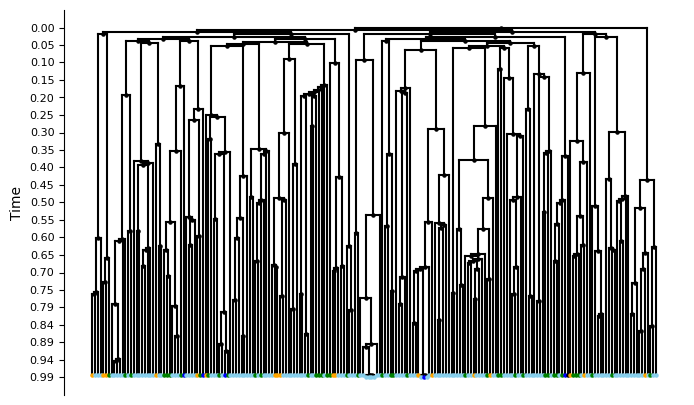

In [32]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [33]:
leaves = [n for n, d in T.out_degree() if d == 0]

In [34]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [35]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9870389566041347 0.9935194794114179


In [36]:
EPS = 1e-4
scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1

In [37]:
for u, v, d in T.edges(data=True):
    d['weight'] *= scale

In [38]:
for leaf in leaves:
    dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    
    if dist > 1.0:
        parent = list(T.predecessors(leaf))[0]
        
        edge_length = T[parent][leaf]['weight']
        
        excess = dist - 1.0
        T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths

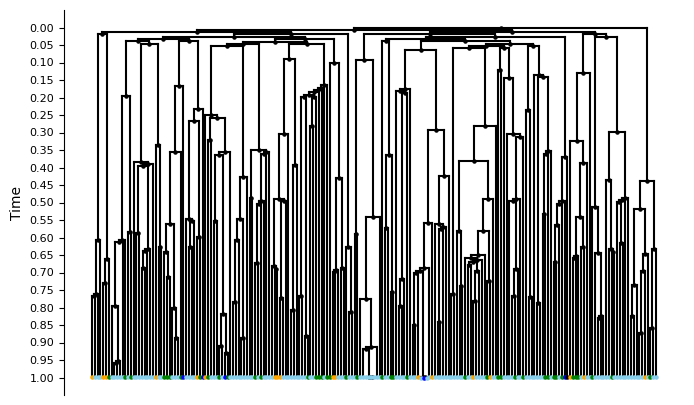

In [39]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [40]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [41]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9999 1.0


In [42]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int,
            {'NMPs': 18,
             'NeuralTube': 139,
             'Somite': 42,
             'Endothelial': 5,
             'PCGLC': 1})

## Differentiation Map from CARTA

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:210: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


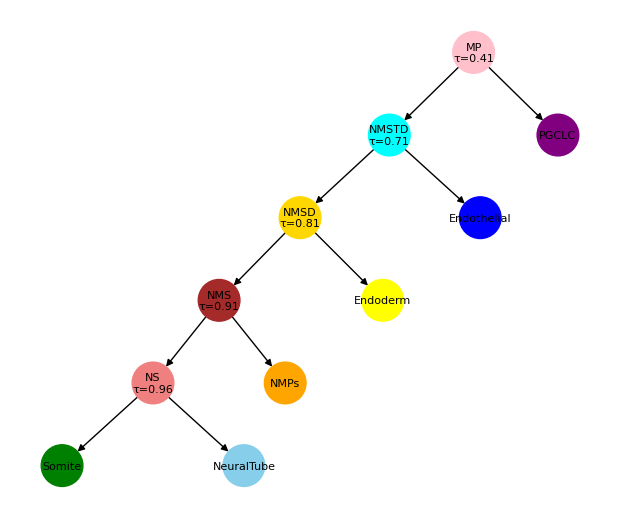

In [43]:
import string
from plotters import plot_differentiation_tree

diff_map_edges = [
    ("MP", "PGCLC"),
    ("MP", "NMSTD"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
]

a = 0.96
b = 0.05
c = 0.1
d = 0.1
e = 0.3

diff_times = {
    "MP":  a- b - c - d - e,
    "NMSTD": a - b - c - d,
    "NMSD": a - b - c,
    "NMS": a - b,
    "NS": a,
    "PGCLC": None,
    "Endothelial": None,
    "Endoderm": None,
    "NMPs": None,
    "Somite": None,
    "NeuralTube": None
}

diff_T = nx.DiGraph()


for k, v in diff_times.items():
    diff_T.add_node(k, diff_time=v)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

In [44]:
from likelihood import add_node_times
T = add_node_times(T, root=T.graph['root'])

In [45]:
rev_diff_T = diff_T.copy()
for n in diff_T.nodes():
    if diff_T.nodes[n]['diff_time'] is None: rev_diff_T.nodes[n]['diff_time'] = 0
    else: rev_diff_T.nodes[n]['diff_time'] = 1 - diff_T.nodes[n]['diff_time']

In [46]:
from likelihood import assign_states_to_internal_nodes

T = assign_states_to_internal_nodes(T, rev_diff_T, correct=True)

Children have > 1 types ['Endothelial', 'NeuralTube'] at 9.999835097185272e-05
Setting state for descendant 248 at 0.0 to ?
Setting state for descendant 249 at 0.0 to ?
Children have > 1 types ['Endothelial', 'NS'] at 0.0710521333042049
Setting state for descendant 105 at 9.999960016737752e-05 to ?
Setting state for descendant 106 at 9.999960016737752e-05 to ?
Children have > 1 types ['PCGLC', 'MP'] at 0.6308254049161346
Setting state for descendant 337 at 0.5032020699641963 to ?
Setting state for descendant 338 at 0.496637108380537 to ?
Setting state for descendant 339 at 0.43500912003669145 to ?
Setting state for descendant 340 at 0.32891719231362815 to ?
Setting state for descendant 341 at 9.999922405756756e-05 to ?
Setting state for descendant 342 at 9.999922405756756e-05 to ?
Setting state for descendant 343 at 9.999922405756756e-05 to ?
Setting state for descendant 344 at 9.999922405756756e-05 to ?
Setting state for descendant 345 at 9.999914433300727e-05 to ?
Setting state for d

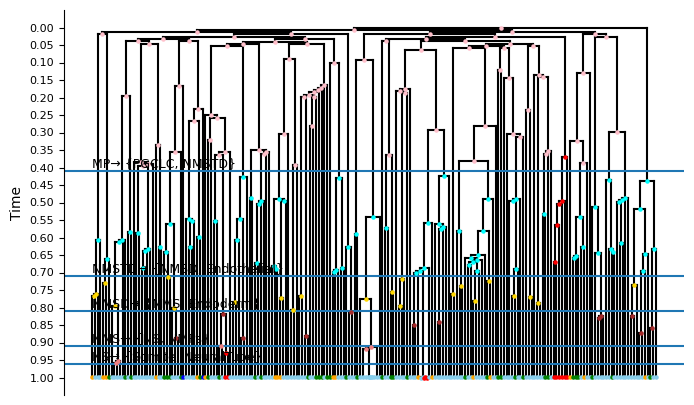

In [47]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T)

In [48]:
types = list(diff_T.nodes())

transition_maps = [
    (i, succ)
    for i in diff_T.nodes()
    if (succ := list(diff_T.successors(i)))
]

print(types)
print(transition_maps)

['MP', 'NMSTD', 'NMSD', 'NMS', 'NS', 'PGCLC', 'Endothelial', 'Endoderm', 'NMPs', 'Somite', 'NeuralTube']
[('MP', ['PGCLC', 'NMSTD']), ('NMSTD', ['NMSD', 'Endothelial']), ('NMSD', ['NMS', 'Endoderm']), ('NMS', ['NS', 'NMPs']), ('NS', ['Somite', 'NeuralTube'])]


### Considering all trees together

In [49]:
len(data)

12

In [50]:
Ts = []

for t in data[2:3]:
    T = ete_to_nx(t)
    Ts.append(T)

In [51]:
## scale edges
EPS = 1e-4

for T in Ts:
    leaves = [n for n, d in T.out_degree() if d == 0]
    # If edges have weight attribute 'length' or similar
    distances = {}
    for leaf in leaves:
        distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1
    for u, v, d in T.edges(data=True):
        d['weight'] *= scale
    
    for leaf in leaves:
        dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
        
        if dist > 1.0:
            parent = list(T.predecessors(leaf))[0]
            
            edge_length = T[parent][leaf]['weight']
            
            excess = dist - 1.0
            T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths
        

In [52]:
## add node times and assign internal states
for i, T in enumerate(Ts):
    print('='*50)
    print('Processing tree', i)
    print('='*50)
    T = add_node_times(T, root=T.graph['root'])
    T = assign_states_to_internal_nodes(T, rev_diff_T, correct=True)

Processing tree 0
Children have > 1 types ['Endothelial', 'NeuralTube'] at 0.012961041768047243
Setting state for descendant 248 at 0.006480520588582062 to ?
Setting state for descendant 249 at 0.006480520588582062 to ?
Children have > 1 types ['Endothelial', 'NS'] at 0.08300056697364289
Setting state for descendant 105 at 0.012961043001175288 to ?
Setting state for descendant 106 at 0.012961043001175288 to ?
Children have > 1 types ['PCGLC', 'MP'] at 0.6355738502486925
Setting state for descendant 337 at 0.5095920486992362 to ?
Setting state for descendant 338 at 0.5031115278154665 to ?
Setting state for descendant 339 at 0.44227621897206115 to ?
Setting state for descendant 340 at 0.33754888059432964 to ?
Setting state for descendant 341 at 0.012961042629903163 to ?
Setting state for descendant 342 at 0.012961042629903163 to ?
Setting state for descendant 343 at 0.012961042629903163 to ?
Setting state for descendant 344 at 0.012961042629903163 to ?
Setting state for descendant 345 at

Drawing tree 0


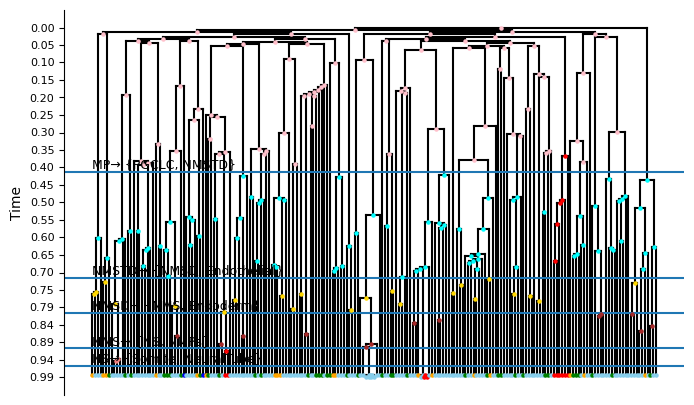

In [53]:
## draw trees
for i, T in enumerate(Ts):
    print('='*50)
    print('Drawing tree', i)
    print('='*50)
    draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T)

In [54]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

from likelihood import calculate_log_likelihood_graph_diff_opt


MAX_DEATH = 1.0
MAX_BIRTH = 10.0


def unpack_params(theta):

    k = 0

    # -------------------------
    # Death rates: (0, 1)
    # -------------------------
    death = {}
    for t in types:
        death[t] = MAX_DEATH * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Birth rates: (death, 10)
    # -------------------------
    birth = {}
    for t in types:
        birth[t] = death[t] + (MAX_BIRTH - death[t]) * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Transition matrix
    # -------------------------
    Q = pd.DataFrame(0.0, index=types, columns=types)

    for i, transition_to in transition_maps:

        logits = []
        js = []

        for j in transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1

        logits = np.array(logits)
        logits -= np.max(logits)

        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()

        for idx, j in enumerate(js):
            Q.loc[i, j] = probs[idx]

    return birth, death, Q


def neg_log_likelihood(theta, trees, diff_T, sampling_rate=1.0):

    birth, death, Q = unpack_params(theta)

    total_nll = 0.0

    for cell_lineage_T in trees:

        # try:
        l = calculate_log_likelihood_graph_diff_opt(
            T=cell_lineage_T,
            birth_rates=birth,
            death_rates=death,
            sampling_rate=sampling_rate,
            transition_probabilities=Q,
            diff_T=diff_T
        )
        
        total_nll += -l

    return total_nll


def pack_initial():

    params = []

    # death parameters
    for t in types:
        params.append(0.0)

    # birth parameters
    for t in types:
        params.append(0.0)

    # transition logits
    for i, transition_to in transition_maps:
        for j in transition_to:
            params.append(0.0)

    return np.array(params)


def find_params(trees, diff_T):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, diff_T, 0.5),
        method="L-BFGS-B"
    )

    print(result)

    birth, death, Q = unpack_params(result.x)

    return birth, death, Q

In [55]:
birth_rates, death_rates, Q = find_params(Ts, rev_diff_T)
birth_rates, death_rates, Q

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 170.13038442865442
        x: [-8.277e+00  9.351e+00 ... -6.327e-01  5.887e-01]
      nit: 24
      jac: [ 4.661e-04 -1.961e-04 ...  8.867e-02 -8.867e-02]
     nfev: 1188
     njev: 36
 hess_inv: <32x32 LbfgsInvHessProduct with dtype=float64>


({'MP': np.float64(5.5093814779731645),
  'NMSTD': np.float64(3.889904308344875),
  'NMSD': np.float64(2.6339305395317756),
  'NMS': np.float64(1.0531860393075108),
  'NS': np.float64(0.9633365030207902),
  'PGCLC': np.float64(1.5151660294292195),
  'Endothelial': np.float64(0.2588421028823034),
  'Endoderm': np.float64(1.657331122338407),
  'NMPs': np.float64(0.13384790896799553),
  'Somite': np.float64(0.27645520755910286),
  'NeuralTube': np.float64(1.973688809766399)},
 {'MP': np.float64(0.0002541625625289463),
  'NMSTD': np.float64(0.9999130878122054),
  'NMSD': np.float64(0.7893031481072575),
  'NMS': np.float64(0.9912550163454326),
  'NS': np.float64(0.9633360142604723),
  'PGCLC': np.float64(0.6783628169203033),
  'Endothelial': np.float64(0.2586644688352604),
  'Endoderm': np.float64(0.5963794568186571),
  'NMPs': np.float64(0.13384737345442577),
  'Somite': np.float64(0.27645503387586173),
  'NeuralTube': np.float64(0.999801655172963)},
               MP  NMSTD      NMSD  NMS

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:210: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


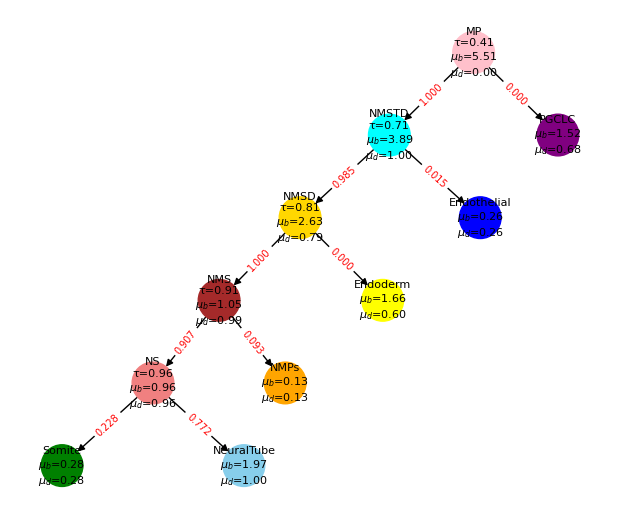

In [56]:
plot_differentiation_tree(diff_T, birth_rates, death_rates, transition_probabilities=Q)

## Multiple diff times

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:210: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


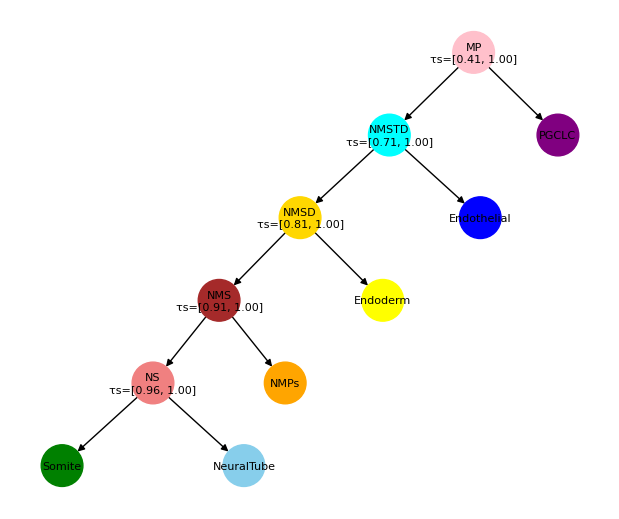

In [144]:
import string
from plotters import plot_differentiation_tree

diff_map_edges = [
    ("MP", "PGCLC"),
    ("MP", "NMSTD"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
]

a = 0.96
b = 0.05
c = 0.1
d = 0.1
e = 0.3

EPS = 1e-10

diff_ts = {
    "MP":  [a- b - c - d - e, 1 - 5*EPS],
    "NMSTD": [a - b - c - d, 1 - 4*EPS],
    "NMSD": [a - b - c, 1 - 3*EPS],
    "NMS": [a - b, 1 - 2*EPS],
    "NS": [a, 1 - 1*EPS],
    "PGCLC": [],
    "Endothelial": [],
    "Endoderm": [],
    "NMPs": [],
    "Somite": [],
    "NeuralTube": []
}

diff_T = nx.DiGraph()


for k, v in diff_ts.items():
    diff_T.add_node(k, diff_times=v)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

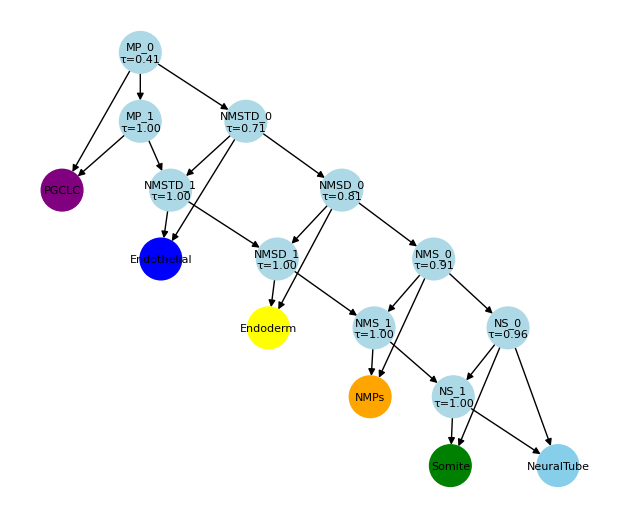

In [145]:
inflated_diff_T = nx.DiGraph()

for n in diff_T.nodes():
    diff_times = diff_T.nodes[n]['diff_times']
    if not diff_times:
        inflated_diff_T.add_node(n, diff_time=None)
    else:
        for i, t in enumerate(diff_times):
            inflated_diff_T.add_node(f"{n}_{i}", diff_time=t)


for u, v in diff_T.edges():
    for i, t in enumerate(diff_T.nodes[u]['diff_times']):
        nearest_v = None
        nearest_v_time = float('inf')
        v_diff_times = diff_T.nodes[v]['diff_times']

        if not v_diff_times:

            inflated_diff_T.add_edge(f"{u}_{i}", v)
            
        else:

            for j, t2 in enumerate(v_diff_times):
                if t2 > t and t2 < nearest_v_time:
                    nearest_v = j
                    nearest_v_time = t2
            
            if nearest_v is not None:
                inflated_diff_T.add_edge(f"{u}_{i}", f"{v}_{nearest_v}")

for n in diff_T.nodes():
    diff_times = diff_T.nodes[n]['diff_times']
    if diff_times and len(diff_times) > 1:
        for i in range(len(diff_times)-1):
            inflated_diff_T.add_edge(f"{n}_{i}", f"{n}_{i+1}")


plot_differentiation_tree(inflated_diff_T)

In [146]:
Ts = []

for t in data[2:3]:
    T = ete_to_nx(t)
    Ts.append(T)

In [147]:
## scale edges
EPS = 1e-4

for T in Ts:
    leaves = [n for n, d in T.out_degree() if d == 0]
    # If edges have weight attribute 'length' or similar
    distances = {}
    for leaf in leaves:
        distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1
    for u, v, d in T.edges(data=True):
        d['weight'] *= scale
    
    for leaf in leaves:
        dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
        
        if dist > 1.0:
            parent = list(T.predecessors(leaf))[0]
            
            edge_length = T[parent][leaf]['weight']
            
            excess = dist - 1.0
            T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths
        

In [148]:
## add node times and assign internal states
for i, T in enumerate(Ts):
    print('='*50)
    print('Processing tree', i)
    print('='*50)
    T = add_node_times(T, root=T.graph['root'])

    leaves = [n for n, d in T.out_degree() if d == 0]
    for leaf in leaves:
        T.nodes[leaf]["T"] = 0

    # T = assign_states_to_internal_nodes(T, rev_diff_T, correct=True)

Processing tree 0


Drawing tree 0


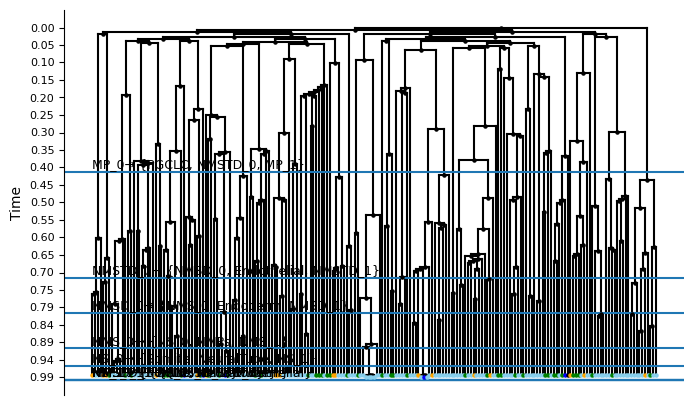

In [149]:
## draw trees
for i, T in enumerate(Ts):
    print('='*50)
    print('Drawing tree', i)
    print('='*50)
    draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=inflated_diff_T)

In [150]:
types = list(inflated_diff_T.nodes())

transition_maps = [
    (i, list(inflated_diff_T.successors(i)))
    for i in inflated_diff_T.nodes()
]

print(types)
print(transition_maps)

['MP_0', 'MP_1', 'NMSTD_0', 'NMSTD_1', 'NMSD_0', 'NMSD_1', 'NMS_0', 'NMS_1', 'NS_0', 'NS_1', 'PGCLC', 'Endothelial', 'Endoderm', 'NMPs', 'Somite', 'NeuralTube']
[('MP_0', ['PGCLC', 'NMSTD_0', 'MP_1']), ('MP_1', ['PGCLC', 'NMSTD_1']), ('NMSTD_0', ['NMSD_0', 'Endothelial', 'NMSTD_1']), ('NMSTD_1', ['NMSD_1', 'Endothelial']), ('NMSD_0', ['NMS_0', 'Endoderm', 'NMSD_1']), ('NMSD_1', ['NMS_1', 'Endoderm']), ('NMS_0', ['NS_0', 'NMPs', 'NMS_1']), ('NMS_1', ['NS_1', 'NMPs']), ('NS_0', ['Somite', 'NeuralTube', 'NS_1']), ('NS_1', ['Somite', 'NeuralTube']), ('PGCLC', []), ('Endothelial', []), ('Endoderm', []), ('NMPs', []), ('Somite', []), ('NeuralTube', [])]


In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

from likelihood import calculate_log_likelihood_graph_diff


MAX_DEATH = 1.0
MAX_BIRTH = 10.0


def unpack_params(theta):

    k = 0

    # -------------------------
    # Death rates: (0, 1)
    # -------------------------
    death = {}
    for t in types:
        death[t] = MAX_DEATH * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Birth rates: (death, 10)
    # -------------------------
    birth = {}
    for t in types:
        birth[t] = death[t] + (MAX_BIRTH - death[t]) * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Transition matrix
    # -------------------------
    Q = pd.DataFrame(0.0, index=types, columns=types)

    for i, transition_to in transition_maps:

        if len(transition_to) == 0:
            # absorbing state
            Q.loc[i, i] = 1.0
            continue

        logits = []
        js = []

        for j in transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1

        logits = np.array(logits)
        logits -= np.max(logits)

        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()

        for idx, j in enumerate(js):
            Q.loc[i, j] = probs[idx]
    
    # print(Q)
    
    return birth, death, Q


def neg_log_likelihood(theta, trees, diff_T, sampling_rate=1.0):

    birth, death, Q = unpack_params(theta)

    total_nll = 0.0

    for cell_lineage_T in trees:

        # try:
        l = calculate_log_likelihood_graph_diff(
            T=cell_lineage_T,
            birth_rates=birth,
            death_rates=death,
            sampling_rate=sampling_rate,
            transition_probabilities=Q,
            diff_T=diff_T
        )
        
        total_nll += -l

    return total_nll


def pack_initial():

    params = []

    # death parameters
    for t in types:
        params.append(0.0)

    # birth parameters
    for t in types:
        params.append(0.0)

    # transition logits
    for i, transition_to in transition_maps:
        for j in transition_to:
            params.append(0.0)

    return np.array(params)


def find_params(trees, diff_T):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, diff_T, 0.5),
        method="L-BFGS-B"
    )

    print(result)

    birth, death, Q = unpack_params(result.x)

    return birth, death, Q

In [157]:
rev_diff_T = inflated_diff_T.copy()
for n in inflated_diff_T.nodes():
    if inflated_diff_T.nodes[n]['diff_time'] is None: rev_diff_T.nodes[n]['diff_time'] = 0
    else: rev_diff_T.nodes[n]['diff_time'] = 1 - inflated_diff_T.nodes[n]['diff_time']

In [158]:
birth_rates, death_rates, Q = find_params(Ts, rev_diff_T)
birth_rates, death_rates, Q

             MP_0      MP_1   NMSTD_0   NMSTD_1    NMSD_0    NMSD_1     NMS_0  \
MP_0          0.0  0.333333  0.333333  0.000000  0.000000  0.000000  0.000000   
MP_1          0.0  0.000000  0.000000  0.500000  0.000000  0.000000  0.000000   
NMSTD_0       0.0  0.000000  0.000000  0.333333  0.333333  0.000000  0.000000   
NMSTD_1       0.0  0.000000  0.000000  0.000000  0.000000  0.500000  0.000000   
NMSD_0        0.0  0.000000  0.000000  0.000000  0.000000  0.333333  0.333333   
NMSD_1        0.0  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
NMS_0         0.0  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
NMS_1         0.0  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
NS_0          0.0  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
NS_1          0.0  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
PGCLC         0.0  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
Endothelial   0.0  0.000000 

RuntimeError: mixture probability p=0 at state PGCLC

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:210: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


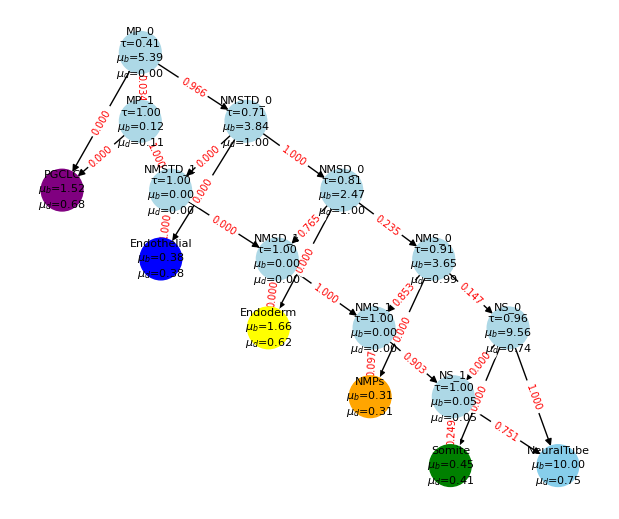

In [81]:
plot_differentiation_tree(inflated_diff_T, birth_rates, death_rates, transition_probabilities=Q)